# 📊 Dashboard RH — Analyse Explicative Post-Modélisation

Ce notebook présente un dashboard explicatif construit **après** la phase de modélisation.  
Il synthétise les informations les plus importantes pour comprendre l'attrition des employés :

- **KPIs globaux** : taux d'attrition, répartition de l'effectif, indicateurs clés
- **Analyse de l'attrition** : par département, rôle, profil démographique
- **Variables importantes** : feature importance du meilleur modèle (Random Forest optimisé)
- **Profil de l'employé à risque** : comparaison des caractéristiques attrition Yes vs No
- **Performance des modèles** : comparaison des métriques ML
- **Impact de l'optimisation** : gain apporté par le tuning bayésien

## 1. Imports & Chargement des données

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style global
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid", palette="muted")

COLORS = {
    'primary':   '#2E86AB',
    'danger':    '#E84855',
    'success':   '#3BB273',
    'warning':   '#F6AE2D',
    'neutral':   '#8D99AE',
    'bg':        '#F8F9FA',
}

# ── Données brutes ──────────────────────────────────────────────────────────
BASE = "Data_origin/"
general   = pd.read_csv(BASE + "general_data.csv")
emp_surv  = pd.read_csv(BASE + "employee_survey_data.csv")
mgr_surv  = pd.read_csv(BASE + "manager_survey_data.csv")

df = (general
      .merge(emp_surv, on="EmployeeID", how="left")
      .merge(mgr_surv, on="EmployeeID", how="left"))

df['Attrition_bin'] = (df['Attrition'] == 'Yes').astype(int)

# ── Résultats des modèles ───────────────────────────────────────────────────
DATA = "Data/"
metrics_df   = pd.read_csv(DATA + "model_comparison_metrics.csv")
times_df     = pd.read_csv(DATA + "model_comparison_times.csv")
optim_df     = pd.read_csv(DATA + "optimization_results.csv")
feat_imp_df  = pd.read_csv(DATA + "final_model_feature_importance.csv")

print(f"✅ Données chargées : {len(df)} employés — {df.columns.nunique()} colonnes")
print(f"   Attrition : {df['Attrition'].value_counts().to_dict()}")

✅ Données chargées : 4410 employés — 30 colonnes
   Attrition : {'No': 3699, 'Yes': 711}


## 2. 🎯 KPIs Globaux

Vue synthétique des indicateurs clés de la population étudiée.

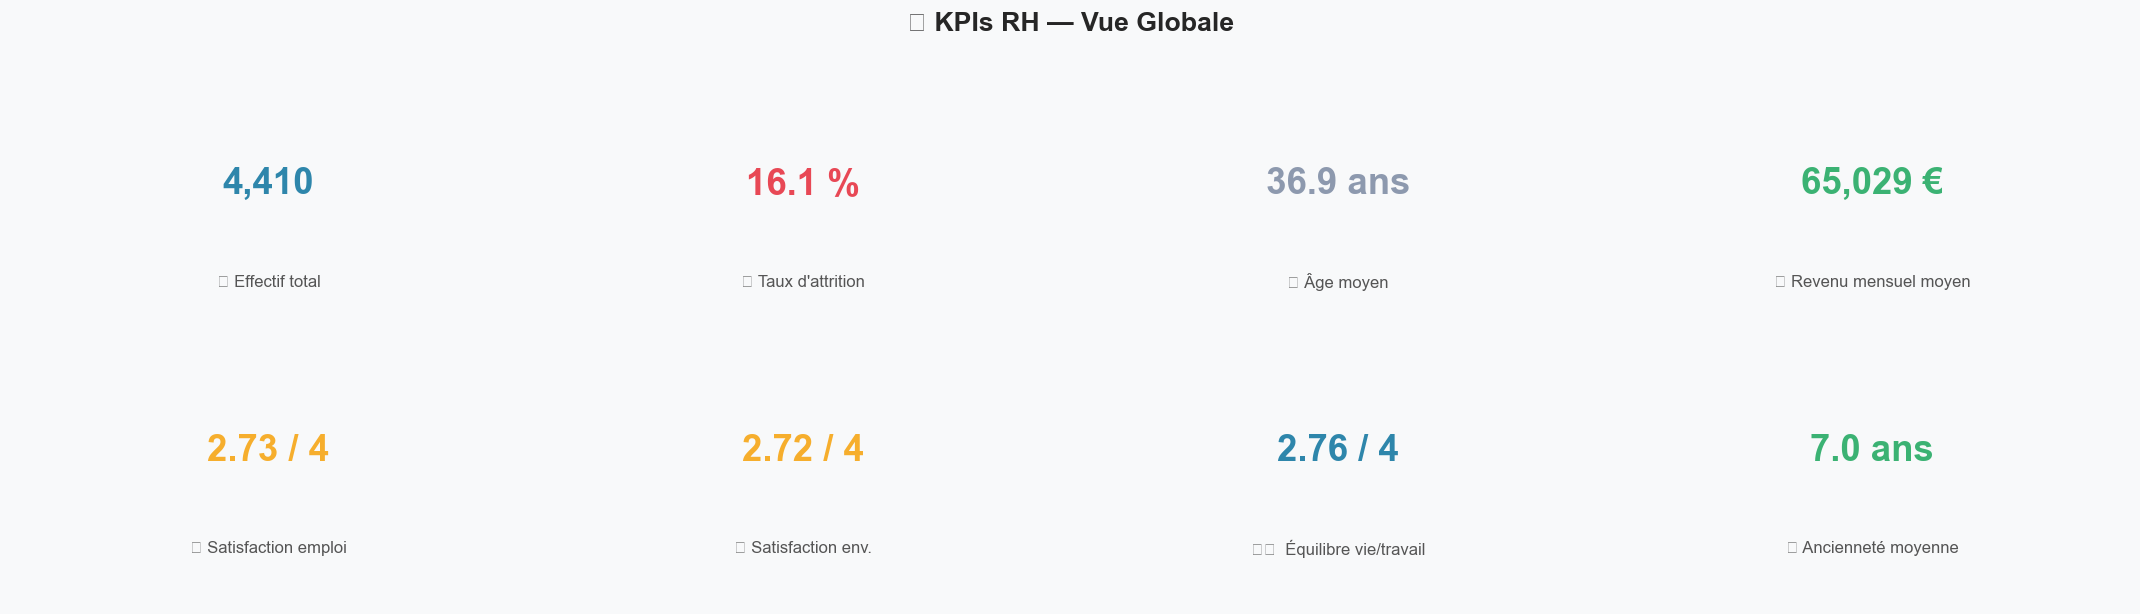


📌 711 employés ont quitté l'entreprise sur 4410 (16.1 %)


In [3]:
# ── Calcul des KPIs ─────────────────────────────────────────────────────────
total_emp       = len(df)
attr_rate       = df['Attrition_bin'].mean() * 100
avg_age         = df['Age'].mean()
avg_income      = df['MonthlyIncome'].mean()
avg_job_sat     = df['JobSatisfaction'].mean()
avg_env_sat     = df['EnvironmentSatisfaction'].mean()
avg_wlb         = df['WorkLifeBalance'].mean()
avg_tenure      = df['YearsAtCompany'].mean()
avg_train       = df['TrainingTimesLastYear'].mean()

kpis = [
    ("👥 Effectif total",          f"{total_emp:,}",             COLORS['primary']),
    ("🚪 Taux d'attrition",        f"{attr_rate:.1f} %",          COLORS['danger']),
    ("🎂 Âge moyen",               f"{avg_age:.1f} ans",          COLORS['neutral']),
    ("💰 Revenu mensuel moyen",    f"{avg_income:,.0f} €",        COLORS['success']),
    ("😊 Satisfaction emploi",     f"{avg_job_sat:.2f} / 4",      COLORS['warning']),
    ("🌿 Satisfaction env.",       f"{avg_env_sat:.2f} / 4",      COLORS['warning']),
    ("⚖️  Équilibre vie/travail",  f"{avg_wlb:.2f} / 4",          COLORS['primary']),
    ("🏢 Ancienneté moyenne",      f"{avg_tenure:.1f} ans",       COLORS['success']),
]

fig, axes = plt.subplots(2, 4, figsize=(18, 5))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("📊 KPIs RH — Vue Globale", fontsize=16, fontweight='bold', y=1.02)

for ax, (label, value, color) in zip(axes.flatten(), kpis):
    ax.set_facecolor('white')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    # Cadre coloré
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(3)
        spine.set_edgecolor(color)
    ax.text(0.5, 0.62, value,  ha='center', va='center',
            fontsize=22, fontweight='bold', color=color)
    ax.text(0.5, 0.22, label,  ha='center', va='center',
            fontsize=10, color='#555555', wrap=True)

plt.tight_layout()
plt.show()
print(f"\n📌 {df['Attrition'].value_counts()['Yes']} employés ont quitté l'entreprise sur {total_emp} ({attr_rate:.1f} %)")

## 3. 🏢 Analyse de l'Attrition par Segment

Distribution de l'attrition selon les grandes dimensions organisationnelles.

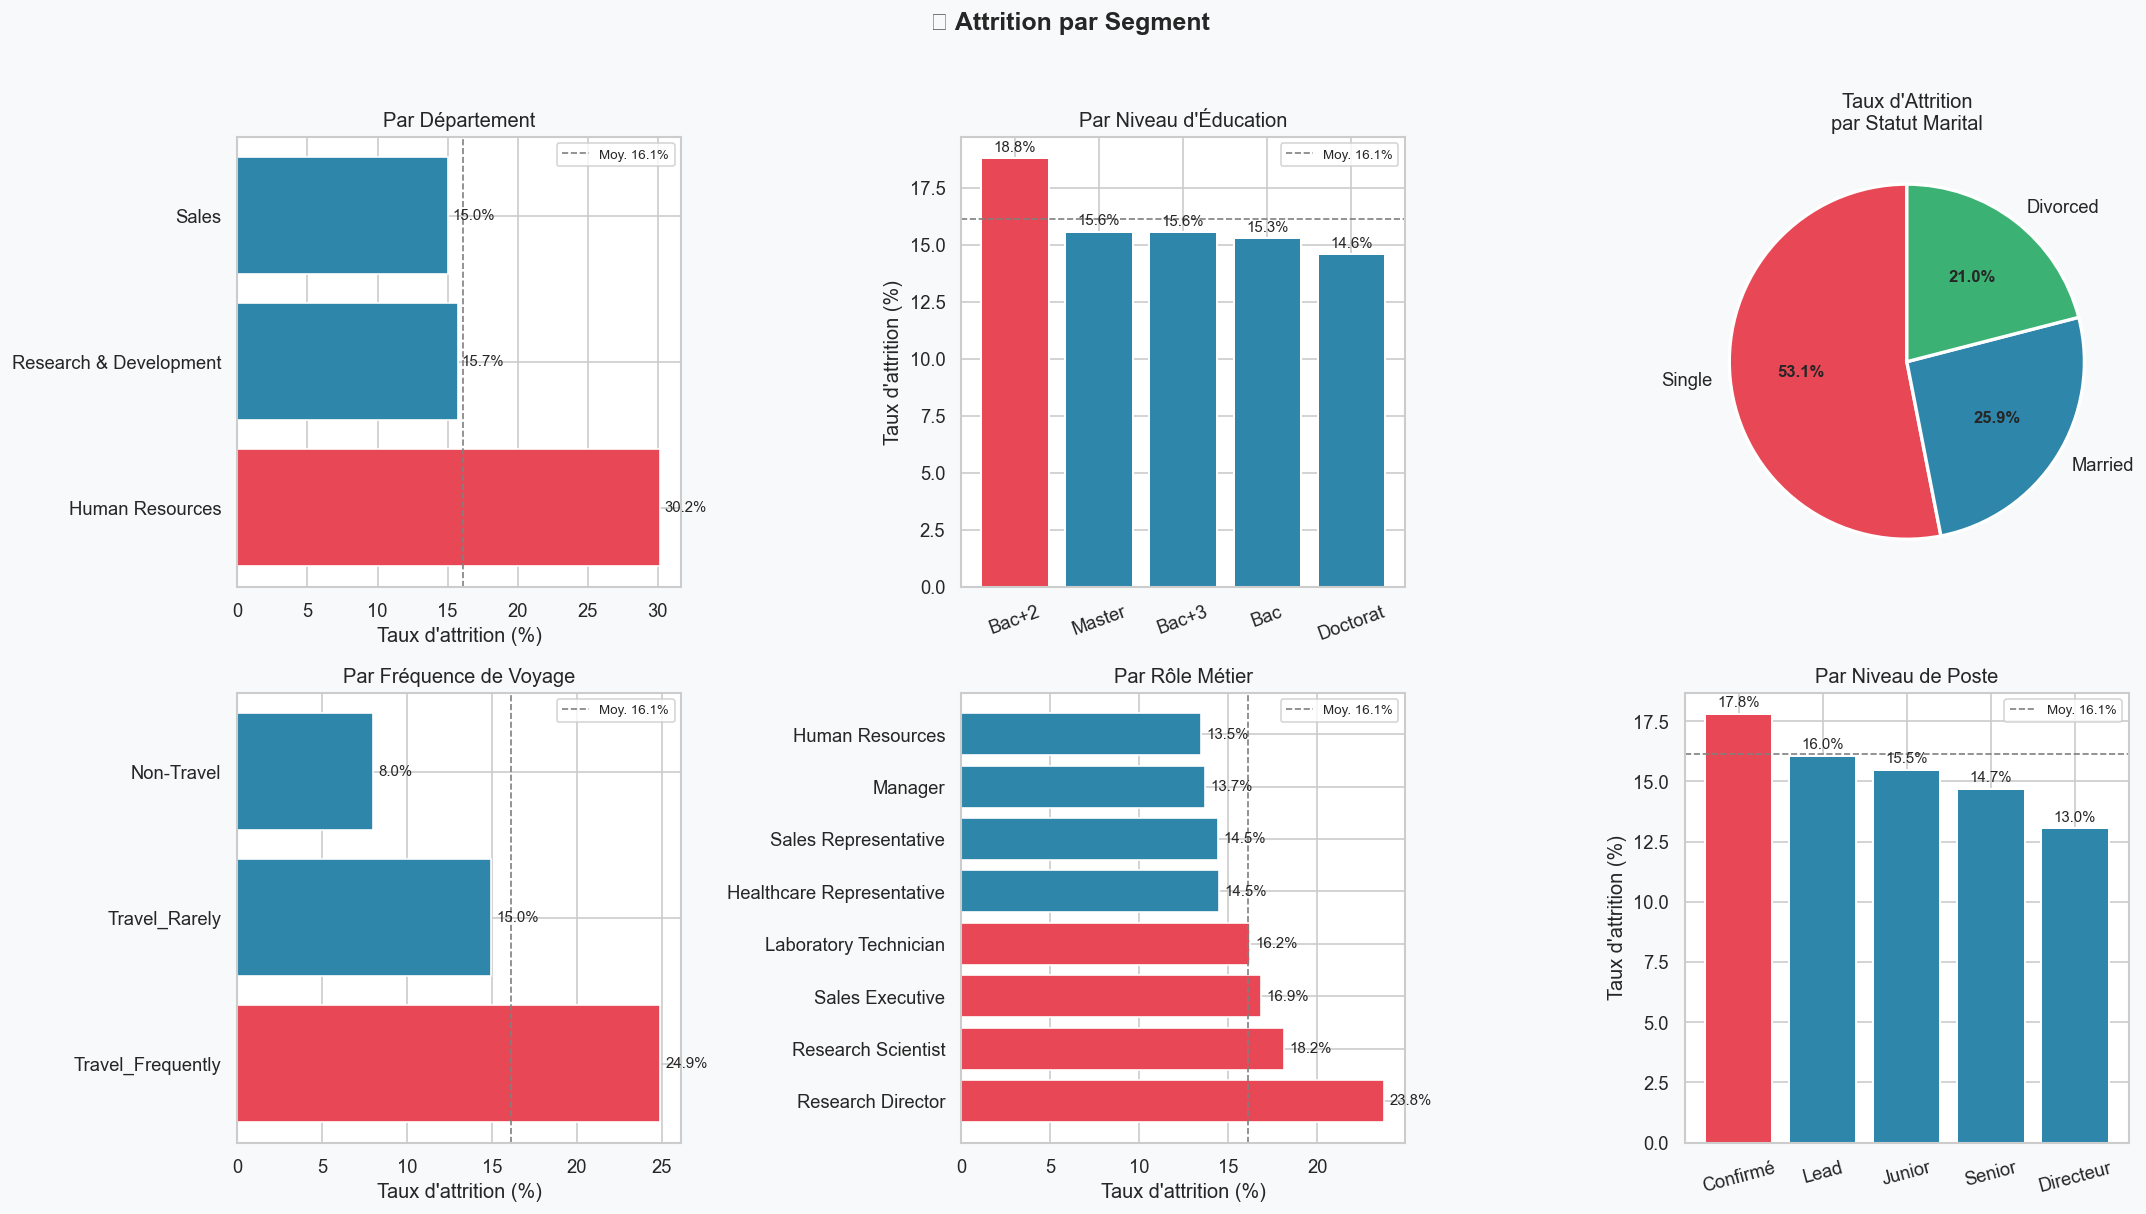

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("🏢 Attrition par Segment", fontsize=15, fontweight='bold', y=1.01)

# ── Helper : taux d'attrition par catégorie ──────────────────────────────────
def attr_rate_by(col, top_n=None):
    grp = df.groupby(col)['Attrition_bin'].agg(['sum', 'count'])
    grp['rate'] = grp['sum'] / grp['count'] * 100
    grp = grp.sort_values('rate', ascending=False)
    if top_n:
        grp = grp.head(top_n)
    return grp

# ① Taux d'attrition par département
ax = axes[0, 0]
d = attr_rate_by('Department')
bars = ax.barh(d.index, d['rate'], color=[COLORS['danger'] if r > attr_rate else COLORS['primary'] for r in d['rate']])
ax.axvline(attr_rate, linestyle='--', color='gray', linewidth=1, label=f'Moy. {attr_rate:.1f}%')
ax.set_xlabel("Taux d'attrition (%)")
ax.set_title("Par Département")
ax.legend(fontsize=8)
for bar, v in zip(bars, d['rate']):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2, f"{v:.1f}%", va='center', fontsize=9)

# ② Taux d'attrition par niveau d'éducation
ax = axes[0, 1]
edu_map = {1: "Bac", 2: "Bac+2", 3: "Bac+3", 4: "Master", 5: "Doctorat"}
df['Education_label'] = df['Education'].map(edu_map)
d = attr_rate_by('Education_label')
bars = ax.bar(d.index, d['rate'],
              color=[COLORS['danger'] if r > attr_rate else COLORS['primary'] for r in d['rate']],
              edgecolor='white', linewidth=1.2)
ax.axhline(attr_rate, linestyle='--', color='gray', linewidth=1, label=f'Moy. {attr_rate:.1f}%')
ax.set_ylabel("Taux d'attrition (%)")
ax.set_title("Par Niveau d'Éducation")
ax.tick_params(axis='x', rotation=20)
ax.legend(fontsize=8)
for bar, v in zip(bars, d['rate']):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.3, f"{v:.1f}%", ha='center', fontsize=9)

# ③ Taux d'attrition par statut marital
ax = axes[0, 2]
d = attr_rate_by('MaritalStatus')
wedge_colors = [COLORS['danger'], COLORS['primary'], COLORS['success']]
wedges, texts, autotexts = ax.pie(
    d['rate'], labels=d.index, autopct='%1.1f%%',
    colors=wedge_colors[:len(d)], startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2))
for at in autotexts:
    at.set_fontsize(10); at.set_fontweight('bold')
ax.set_title("Taux d'Attrition\npar Statut Marital")

# ④ Taux d'attrition par voyage d'affaires
ax = axes[1, 0]
d = attr_rate_by('BusinessTravel')
bars = ax.barh(d.index, d['rate'], color=[COLORS['danger'] if r > attr_rate else COLORS['primary'] for r in d['rate']])
ax.axvline(attr_rate, linestyle='--', color='gray', linewidth=1, label=f'Moy. {attr_rate:.1f}%')
ax.set_xlabel("Taux d'attrition (%)")
ax.set_title("Par Fréquence de Voyage")
ax.legend(fontsize=8)
for bar, v in zip(bars, d['rate']):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2, f"{v:.1f}%", va='center', fontsize=9)

# ⑤ Top 8 rôles par taux d'attrition
ax = axes[1, 1]
d = attr_rate_by('JobRole', top_n=8)
bars = ax.barh(d.index, d['rate'], color=[COLORS['danger'] if r > attr_rate else COLORS['primary'] for r in d['rate']])
ax.axvline(attr_rate, linestyle='--', color='gray', linewidth=1, label=f'Moy. {attr_rate:.1f}%')
ax.set_xlabel("Taux d'attrition (%)")
ax.set_title("Par Rôle Métier")
ax.legend(fontsize=8)
for bar, v in zip(bars, d['rate']):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2, f"{v:.1f}%", va='center', fontsize=9)

# ⑥ Attrition par niveau de poste (JobLevel)
ax = axes[1, 2]
jl_map = {1: "Junior", 2: "Confirmé", 3: "Senior", 4: "Lead", 5: "Directeur"}
df['JobLevel_label'] = df['JobLevel'].map(jl_map)
d = attr_rate_by('JobLevel_label')
bars = ax.bar(d.index, d['rate'],
              color=[COLORS['danger'] if r > attr_rate else COLORS['primary'] for r in d['rate']],
              edgecolor='white', linewidth=1.2)
ax.axhline(attr_rate, linestyle='--', color='gray', linewidth=1, label=f'Moy. {attr_rate:.1f}%')
ax.set_ylabel("Taux d'attrition (%)")
ax.set_title("Par Niveau de Poste")
ax.tick_params(axis='x', rotation=15)
ax.legend(fontsize=8)
for bar, v in zip(bars, d['rate']):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.3, f"{v:.1f}%", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 4. 🔍 Feature Importance — Variables Clés du Modèle

Le **Random Forest optimisé** (meilleur modèle) permet d'identifier les variables qui influencent le plus la prédiction d'attrition.

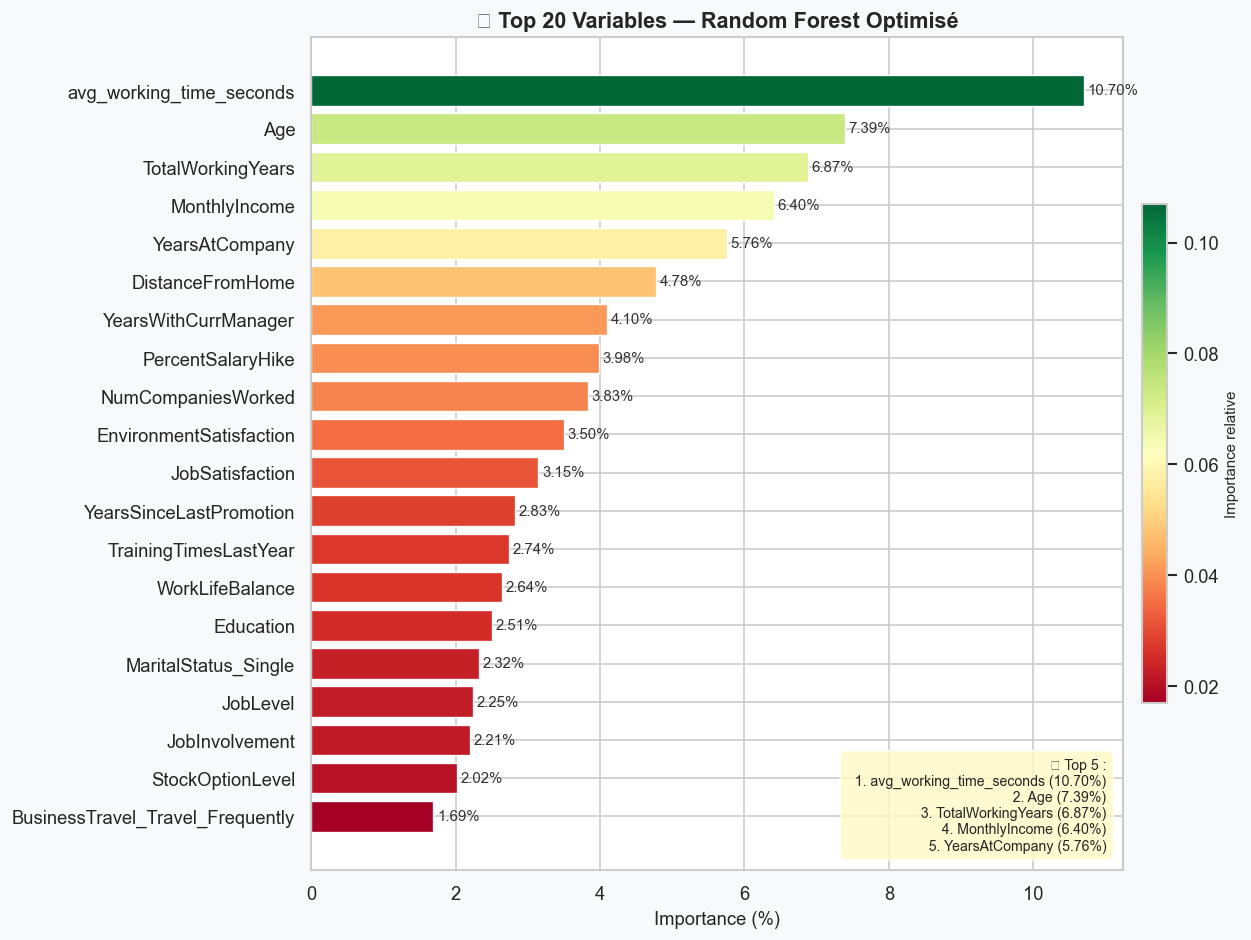


📋 Tableau complet des importances :
                          feature  Importance (%)
         avg_working_time_seconds          10.700
                              Age           7.385
                TotalWorkingYears           6.875
                    MonthlyIncome           6.405
                   YearsAtCompany           5.758
                 DistanceFromHome           4.778
             YearsWithCurrManager           4.104
                PercentSalaryHike           3.979
               NumCompaniesWorked           3.833
          EnvironmentSatisfaction           3.504
                  JobSatisfaction           3.145
          YearsSinceLastPromotion           2.829
            TrainingTimesLastYear           2.739
                  WorkLifeBalance           2.644
                        Education           2.508
             MaritalStatus_Single           2.318
                         JobLevel           2.247
                   JobInvolvement           2.206
             

In [6]:
TOP_N = 20
top_feat = feat_imp_df.sort_values('importance', ascending=True).tail(TOP_N)

fig, ax = plt.subplots(figsize=(11, 8))
fig.patch.set_facecolor(COLORS['bg'])

# Palette dégradée selon l'importance
norm = plt.Normalize(top_feat['importance'].min(), top_feat['importance'].max())
colors = plt.cm.RdYlGn(norm(top_feat['importance'].values))

bars = ax.barh(top_feat['feature'], top_feat['importance'] * 100,
               color=colors, edgecolor='white', linewidth=0.8)

# Annotations sur les barres
for bar, v in zip(bars, top_feat['importance'] * 100):
    ax.text(v + 0.05, bar.get_y() + bar.get_height()/2,
            f"{v:.2f}%", va='center', fontsize=9, color='#333333')

ax.set_xlabel("Importance (%)", fontsize=11)
ax.set_title(f"🌲 Top {TOP_N} Variables — Random Forest Optimisé", fontsize=13, fontweight='bold')
ax.set_facecolor('white')

# Légende colorbar
sm = plt.cm.ScalarMappable(cmap='RdYlGn', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Importance relative", fontsize=9)

# Top 5 encadré
top5 = feat_imp_df.nlargest(5, 'importance')
top5_text = "\n".join([f"  {i+1}. {r.feature} ({r.importance*100:.2f}%)"
                       for i, r in enumerate(top5.itertuples())])
ax.text(0.98, 0.02, f"🏆 Top 5 :\n{top5_text}",
        transform=ax.transAxes, fontsize=8.5,
        va='bottom', ha='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#FFF9C4', alpha=0.8))

plt.tight_layout()
plt.show()

print("\n📋 Tableau complet des importances :")
print(feat_imp_df.sort_values('importance', ascending=False)
      .assign(importance_pct=lambda x: (x['importance']*100).round(3))
      [['feature', 'importance_pct']].rename(columns={'importance_pct': 'Importance (%)'})
      .to_string(index=False))

## 5. 📈 Analyse Détaillée des Top Variables

Distribution des 8 variables les plus importantes selon l'attrition (Yes vs No).

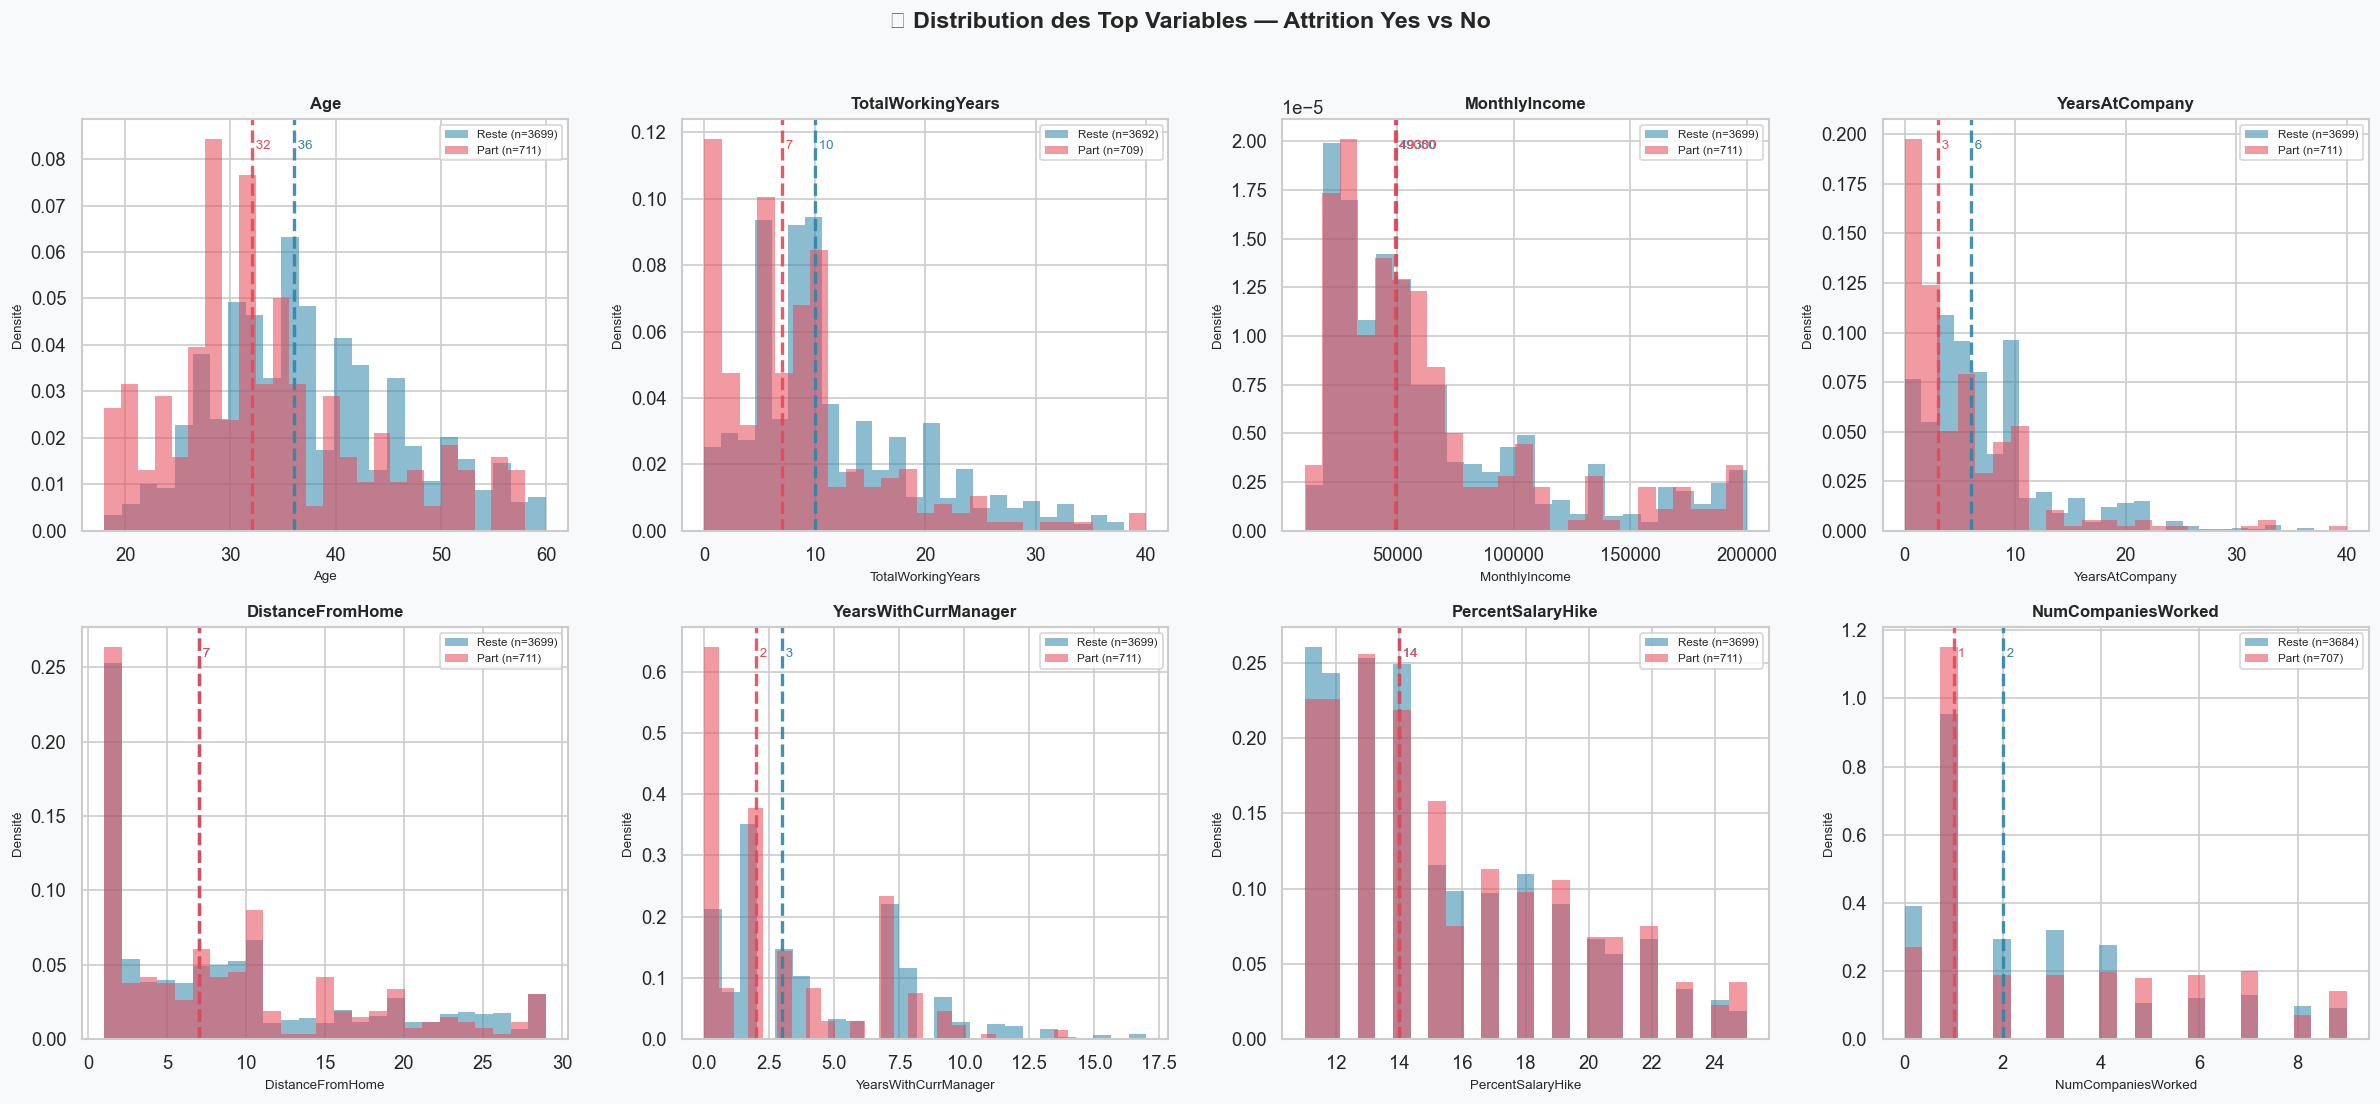

In [7]:
# Top 8 variables numériques disponibles dans les données brutes
top_numerical = ['Age', 'TotalWorkingYears', 'MonthlyIncome', 'YearsAtCompany',
                 'DistanceFromHome', 'YearsWithCurrManager', 'PercentSalaryHike',
                 'NumCompaniesWorked']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("📈 Distribution des Top Variables — Attrition Yes vs No",
             fontsize=14, fontweight='bold', y=1.02)

palette = {'No': COLORS['primary'], 'Yes': COLORS['danger']}

for ax, col in zip(axes.flatten(), top_numerical):
    # Histogramme superposé
    for attrition_val, color in palette.items():
        subset = df[df['Attrition'] == attrition_val][col].dropna()
        ax.hist(subset, bins=25, alpha=0.55, color=color,
                label=f"{'Reste' if attrition_val=='No' else 'Part'} (n={len(subset)})",
                density=True, edgecolor='none')
    # Médianes
    for attrition_val, color in palette.items():
        med = df[df['Attrition'] == attrition_val][col].median()
        ax.axvline(med, color=color, linewidth=2, linestyle='--', alpha=0.9)
        ax.text(med, ax.get_ylim()[1] * 0.95, f" {med:.0f}",
                color=color, fontsize=8, va='top')
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel("Densité", fontsize=8)
    ax.legend(fontsize=7)
    ax.set_facecolor('white')

plt.tight_layout()
plt.show()

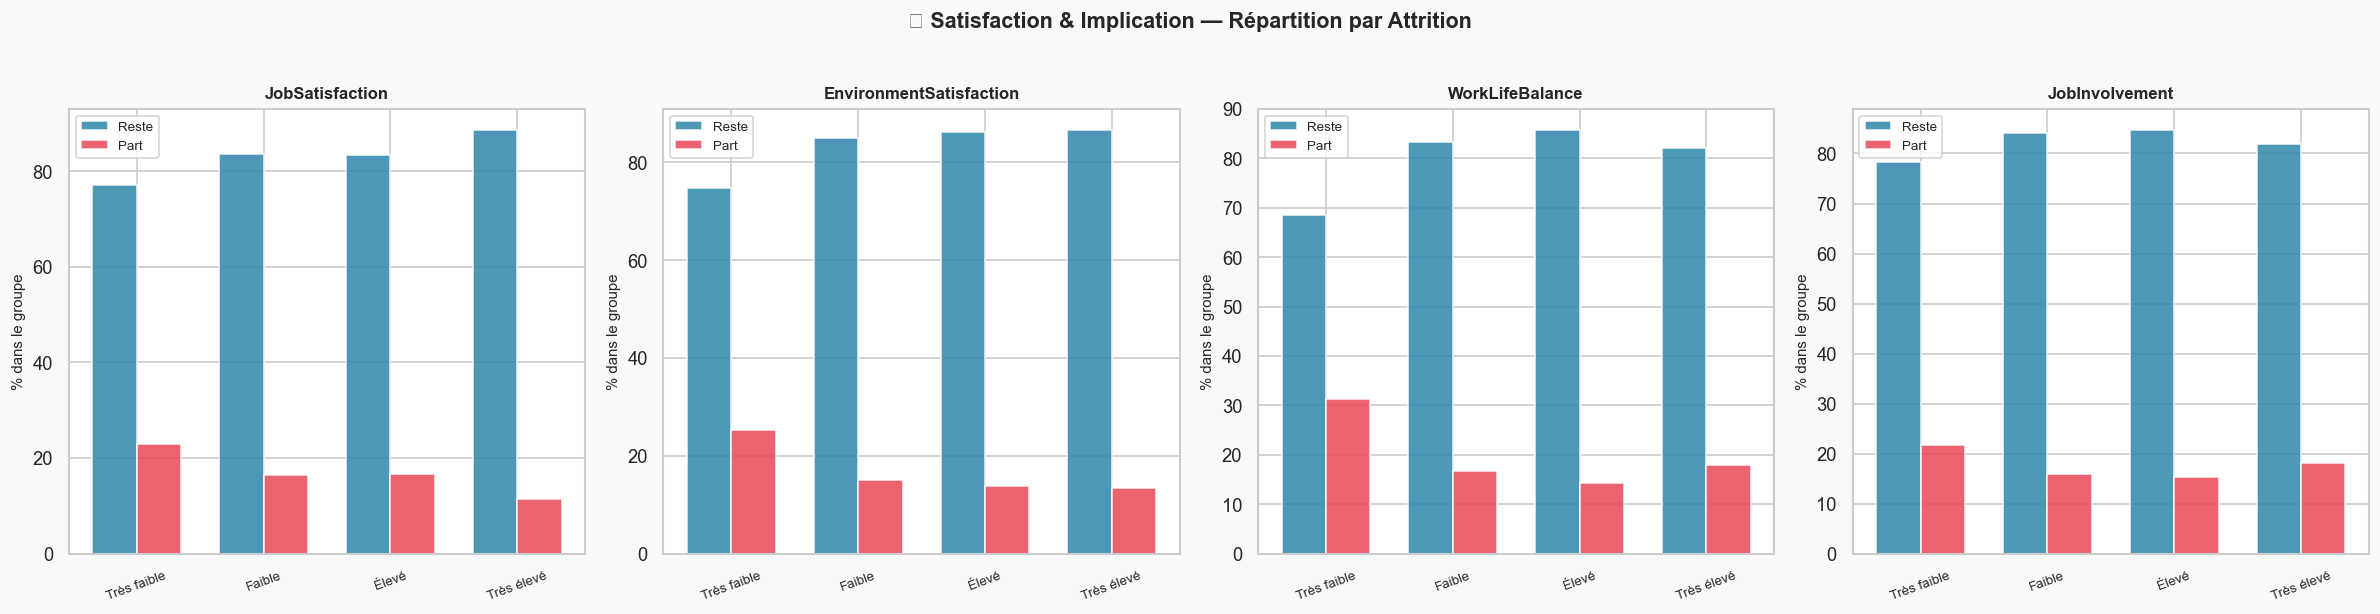

In [8]:
# ── Variables de satisfaction (ordinales 1-4) ────────────────────────────────
sat_vars = ['JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance', 'JobInvolvement']
sat_labels = {1: "Très faible", 2: "Faible", 3: "Élevé", 4: "Très élevé"}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("😊 Satisfaction & Implication — Répartition par Attrition",
             fontsize=13, fontweight='bold', y=1.02)

for ax, col in zip(axes, sat_vars):
    crosstab = pd.crosstab(df[col], df['Attrition'], normalize='index') * 100
    crosstab = crosstab.sort_index()
    x = np.arange(len(crosstab))
    width = 0.35
    ax.bar(x - width/2, crosstab.get('No', pd.Series(0, index=crosstab.index)),
           width, label='Reste', color=COLORS['primary'], alpha=0.85, edgecolor='white')
    ax.bar(x + width/2, crosstab.get('Yes', pd.Series(0, index=crosstab.index)),
           width, label='Part', color=COLORS['danger'], alpha=0.85, edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels([sat_labels.get(i, str(i)) for i in crosstab.index],
                       rotation=20, fontsize=8)
    ax.set_ylabel("% dans le groupe", fontsize=9)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_facecolor('white')

plt.tight_layout()
plt.show()

## 6. 🧑‍💼 Profil de l'Employé à Risque

Comparaison des médianes/moyennes des variables numériques clés entre les employés qui partent (Attrition = Yes) et ceux qui restent (No).

Variable                          Reste     Part        Δ      Δ %
Age                               36.00    32.00    -4.00 🔻  11.1%
MonthlyIncome                  49300.00 49080.00  -220.00 🔻   0.4%
TotalWorkingYears                 10.00     7.00    -3.00 🔻  30.0%
YearsAtCompany                     6.00     3.00    -3.00 🔻  50.0%
DistanceFromHome                   7.00     7.00     0.00 🔻   0.0%
YearsWithCurrManager               3.00     2.00    -1.00 🔻  33.3%
PercentSalaryHike                 14.00    14.00     0.00 🔻   0.0%
NumCompaniesWorked                 2.00     1.00    -1.00 🔻  50.0%
JobSatisfaction                    3.00     3.00     0.00 🔻   0.0%
EnvironmentSatisfaction            3.00     3.00     0.00 🔻   0.0%
WorkLifeBalance                    3.00     3.00     0.00 🔻   0.0%
TrainingTimesLastYear              3.00     3.00     0.00 🔻   0.0%
YearsSinceLastPromotion            1.00     1.00     0.00 🔻   0.0%


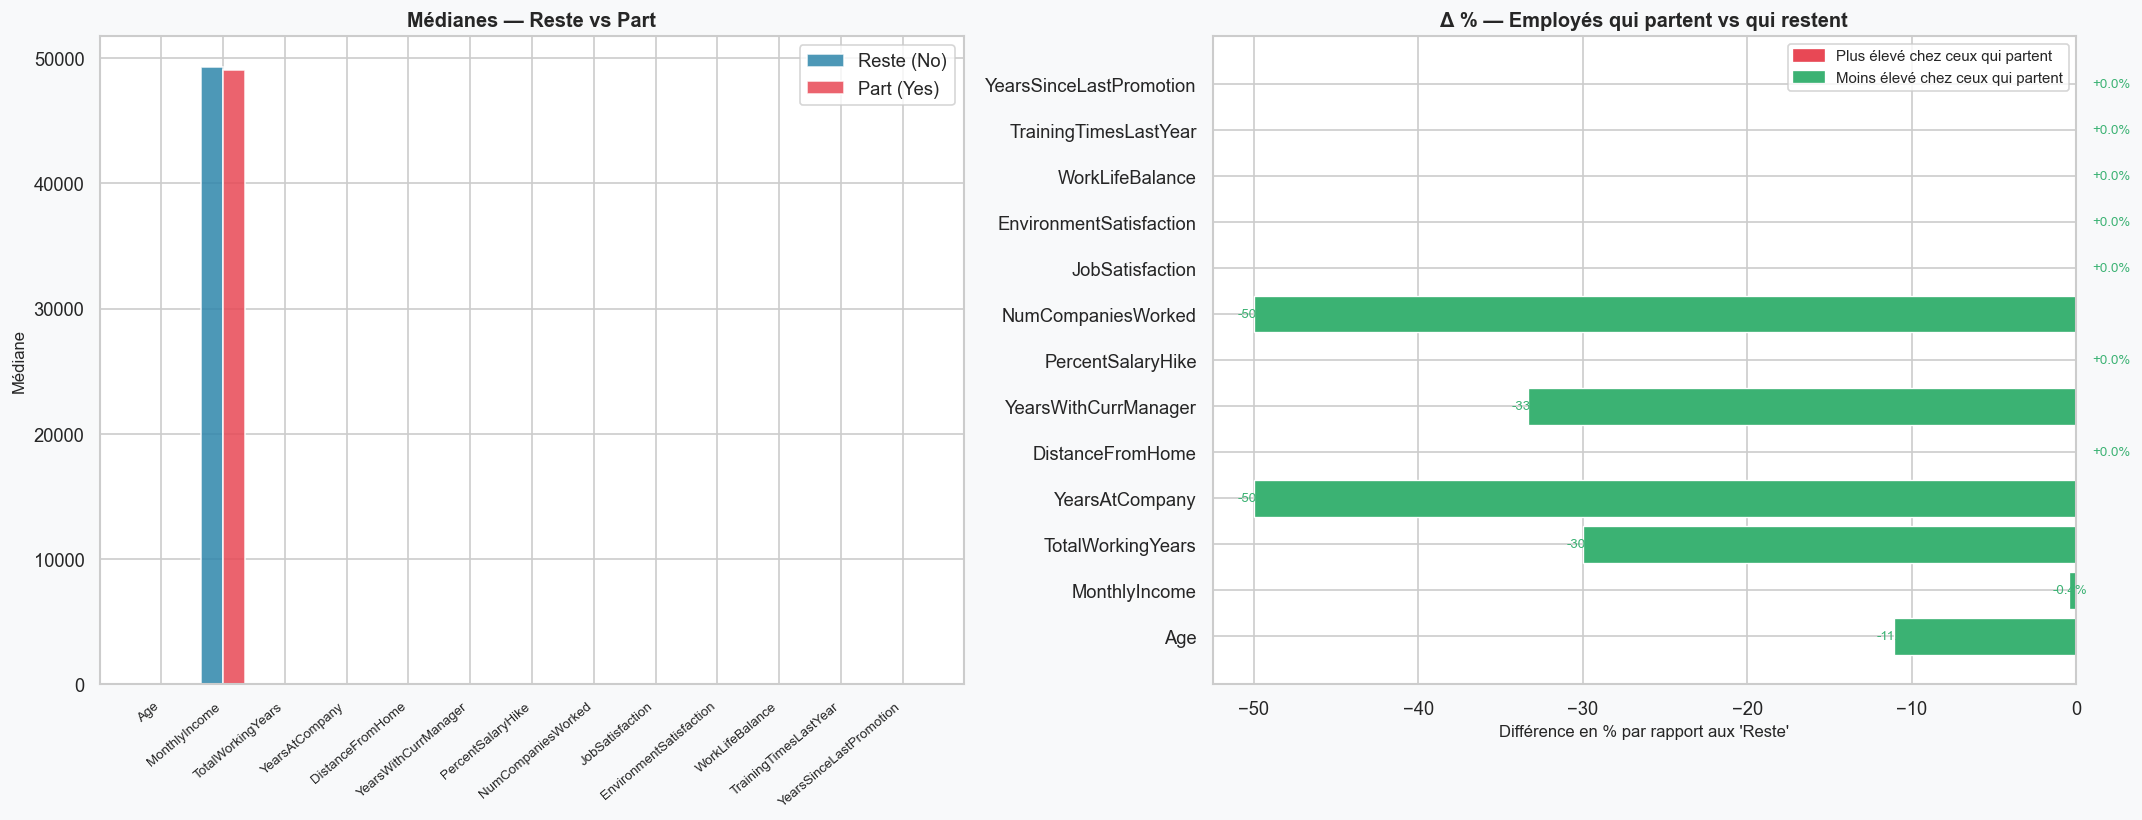

In [9]:
# ── Tableau comparatif ────────────────────────────────────────────────────────
profile_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
                'DistanceFromHome', 'YearsWithCurrManager', 'PercentSalaryHike',
                'NumCompaniesWorked', 'JobSatisfaction', 'EnvironmentSatisfaction',
                'WorkLifeBalance', 'TrainingTimesLastYear', 'YearsSinceLastPromotion']

profile = df.groupby('Attrition')[profile_cols].median().T.rename(columns={'No': 'Reste (No)', 'Yes': 'Part (Yes)'})
profile['Delta (Yes - No)'] = profile['Part (Yes)'] - profile['Reste (No)']
profile['Delta %'] = (profile['Delta (Yes - No)'] / profile['Reste (No)'] * 100).round(1)

print("=" * 65)
print(f"{'Variable':<30} {'Reste':>8} {'Part':>8} {'Δ':>8} {'Δ %':>8}")
print("=" * 65)
for col, row in profile.iterrows():
    sign  = "🔺" if row['Delta (Yes - No)'] > 0 else "🔻"
    print(f"{col:<30} {row['Reste (No)']:>8.2f} {row['Part (Yes)']:>8.2f} "
          f"{row['Delta (Yes - No)']:>8.2f} {sign}{abs(row['Delta %']):>6.1f}%")
print("=" * 65)

# ── Visualisation radar-like : barres normalisées ─────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor(COLORS['bg'])

# Subplot 1 : Valeurs absolues des médianes
x = np.arange(len(profile_cols))
width = 0.35
b1 = ax1.bar(x - width/2, profile['Reste (No)'], width, label='Reste (No)',
             color=COLORS['primary'], alpha=0.85, edgecolor='white')
b2 = ax1.bar(x + width/2, profile['Part (Yes)'], width, label='Part (Yes)',
             color=COLORS['danger'], alpha=0.85, edgecolor='white')
ax1.set_xticks(x)
ax1.set_xticklabels(profile_cols, rotation=40, ha='right', fontsize=8)
ax1.set_ylabel("Médiane", fontsize=10)
ax1.set_title("Médianes — Reste vs Part", fontsize=12, fontweight='bold')
ax1.legend()
ax1.set_facecolor('white')

# Subplot 2 : Delta % (positif = part ont plus, négatif = part ont moins)
delta = profile['Delta %']
colors_d = [COLORS['danger'] if v > 0 else COLORS['success'] for v in delta]
bars = ax2.barh(profile_cols, delta, color=colors_d, edgecolor='white', linewidth=0.8)
ax2.axvline(0, color='black', linewidth=1)
ax2.set_xlabel("Différence en % par rapport aux 'Reste'", fontsize=10)
ax2.set_title("Δ % — Employés qui partent vs qui restent", fontsize=12, fontweight='bold')
ax2.set_facecolor('white')
for bar, v in zip(bars, delta):
    ax2.text(v + (1 if v >= 0 else -1), bar.get_y() + bar.get_height()/2,
             f"{v:+.1f}%", va='center', fontsize=8,
             color=COLORS['danger'] if v > 0 else COLORS['success'])

patches = [mpatches.Patch(color=COLORS['danger'], label='Plus élevé chez ceux qui partent'),
           mpatches.Patch(color=COLORS['success'], label='Moins élevé chez ceux qui partent')]
ax2.legend(handles=patches, fontsize=9)

plt.tight_layout()
plt.show()

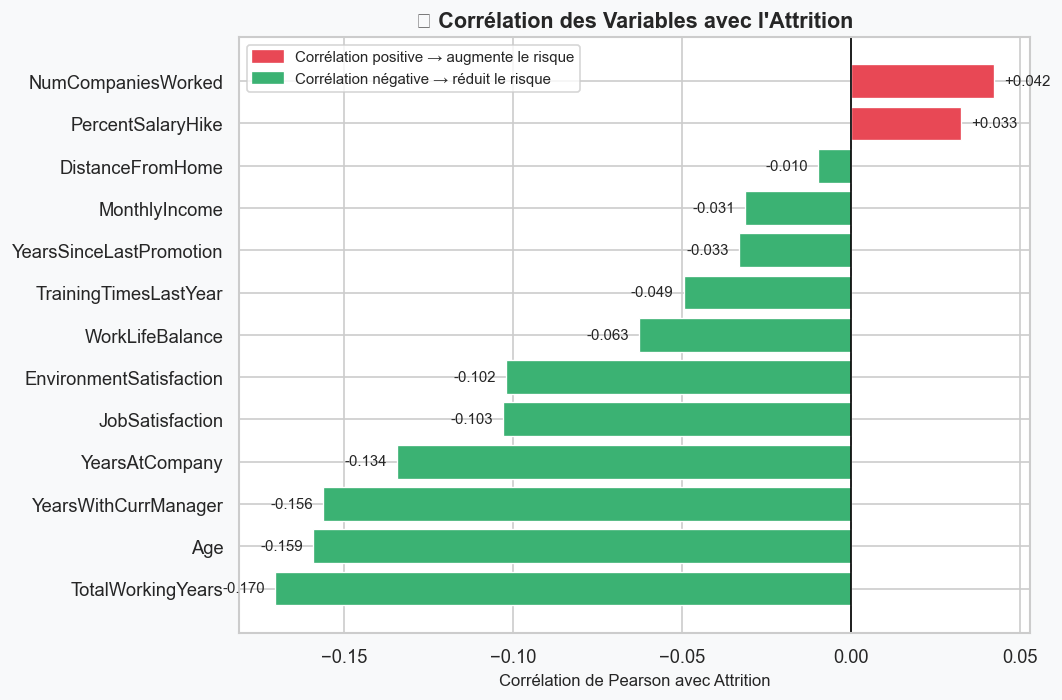

In [10]:
# ── Heatmap de corrélation avec l'attrition ─────────────────────────────────
num_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
            'DistanceFromHome', 'YearsWithCurrManager', 'PercentSalaryHike',
            'NumCompaniesWorked', 'JobSatisfaction', 'EnvironmentSatisfaction',
            'WorkLifeBalance', 'TrainingTimesLastYear', 'YearsSinceLastPromotion',
            'Attrition_bin']

corr_with_attr = df[num_cols].corr()['Attrition_bin'].drop('Attrition_bin').sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
fig.patch.set_facecolor(COLORS['bg'])
ax.set_facecolor('white')

colors_c = [COLORS['danger'] if v > 0 else COLORS['success'] for v in corr_with_attr]
bars = ax.barh(corr_with_attr.index, corr_with_attr.values,
               color=colors_c, edgecolor='white', linewidth=0.8)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel("Corrélation de Pearson avec Attrition", fontsize=10)
ax.set_title("📊 Corrélation des Variables avec l'Attrition", fontsize=13, fontweight='bold')

for bar, v in zip(bars, corr_with_attr.values):
    ax.text(v + (0.003 if v >= 0 else -0.003), bar.get_y() + bar.get_height()/2,
            f"{v:+.3f}", va='center', ha='left' if v >= 0 else 'right', fontsize=9)

patches = [mpatches.Patch(color=COLORS['danger'], label='Corrélation positive → augmente le risque'),
           mpatches.Patch(color=COLORS['success'], label='Corrélation négative → réduit le risque')]
ax.legend(handles=patches, fontsize=9)

plt.tight_layout()
plt.show()

## 7. 🤖 Performance des Modèles ML

Comparaison des 7 modèles testés sur les métriques principales.

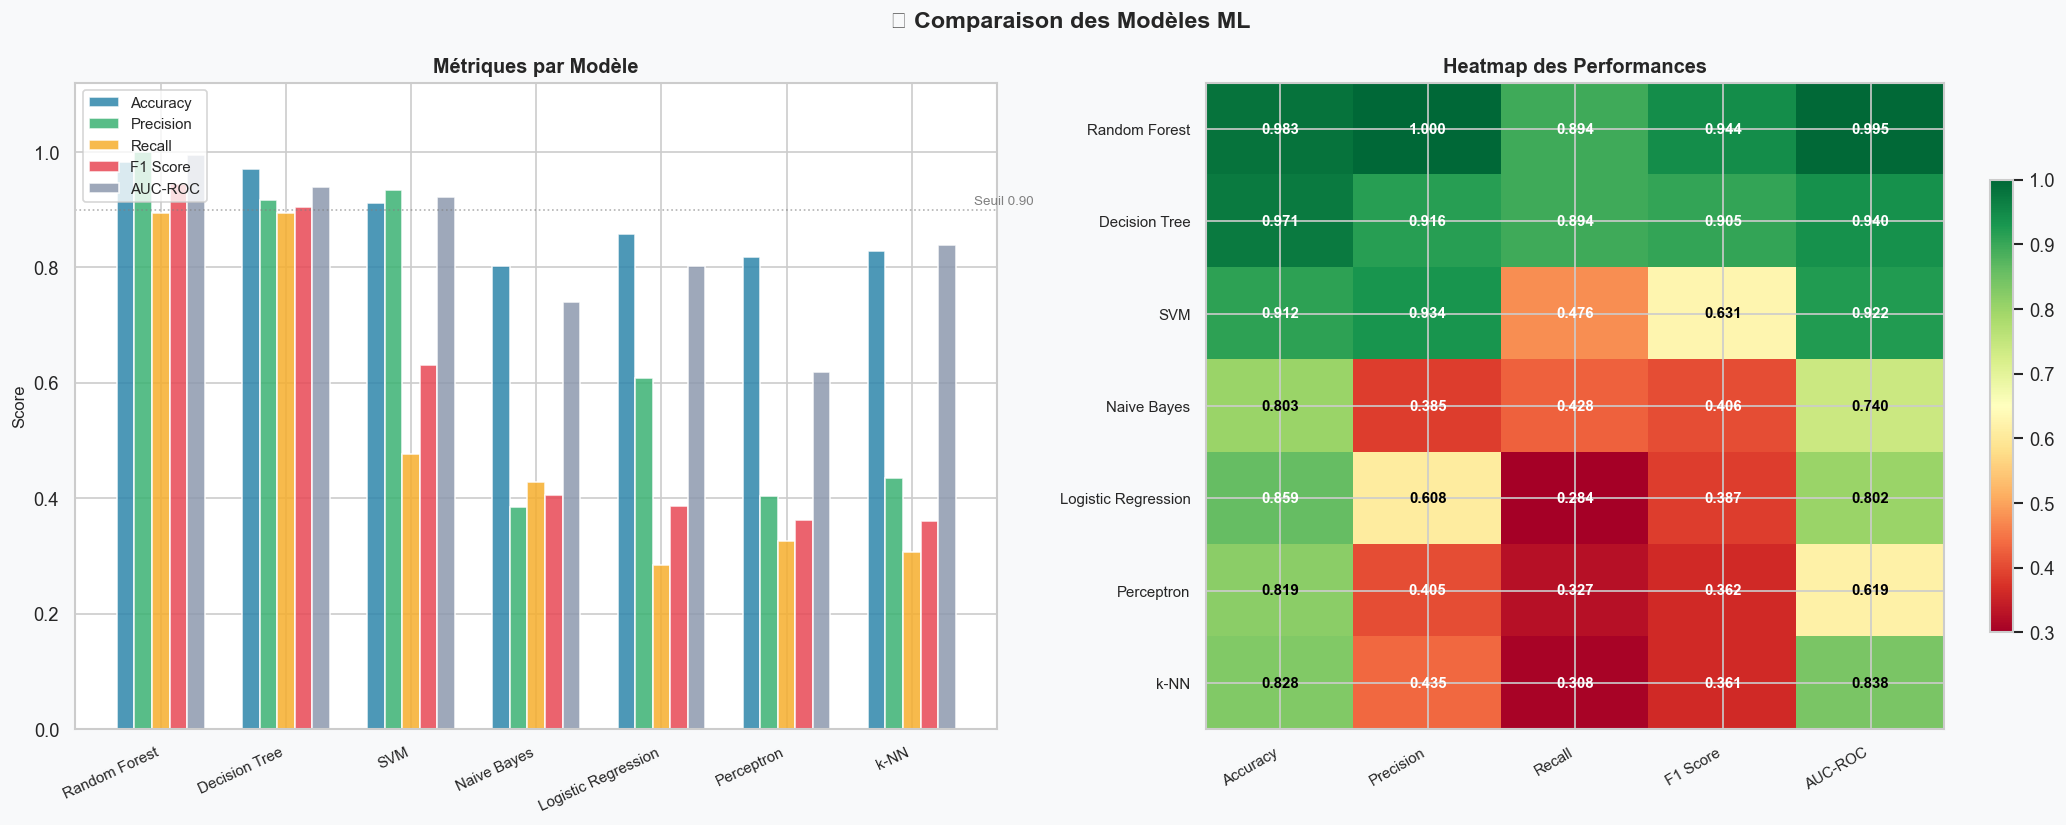


📋 Tableau récapitulatif :
              Model  Accuracy  Precision  Recall  F1 Score  AUC-ROC
      Random Forest    0.9834     1.0000  0.8942    0.9442   0.9949
      Decision Tree    0.9705     0.9163  0.8942    0.9051   0.9395
                SVM    0.9123     0.9340  0.4760    0.6306   0.9225
        Naive Bayes    0.8027     0.3853  0.4279    0.4055   0.7398
Logistic Regression    0.8587     0.6082  0.2837    0.3869   0.8024
         Perceptron    0.8186     0.4048  0.3269    0.3617   0.6186
               k-NN    0.8284     0.4354  0.3077    0.3606   0.8383


In [11]:
metrics_to_show = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
models_order = metrics_df.sort_values('F1 Score', ascending=False)['Model'].tolist()
metrics_df_sorted = metrics_df.set_index('Model').loc[models_order]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("🤖 Comparaison des Modèles ML", fontsize=14, fontweight='bold')

# ── Subplot 1 : Barres groupées ─────────────────────────────────────────────
ax = axes[0]
x = np.arange(len(models_order))
bar_w = 0.14
metric_colors = [COLORS['primary'], COLORS['success'], COLORS['warning'],
                 COLORS['danger'], COLORS['neutral']]

for i, (metric, color) in enumerate(zip(metrics_to_show, metric_colors)):
    vals = metrics_df_sorted[metric].values
    offset = (i - len(metrics_to_show)/2 + 0.5) * bar_w
    bars = ax.bar(x + offset, vals, bar_w, label=metric, color=color, alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(models_order, rotation=25, ha='right', fontsize=9)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score", fontsize=10)
ax.set_title("Métriques par Modèle", fontsize=12, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.set_facecolor('white')
ax.axhline(0.9, color='gray', linestyle=':', linewidth=1, alpha=0.6)
ax.text(len(models_order) - 0.5, 0.91, "Seuil 0.90", color='gray', fontsize=8)

# ── Subplot 2 : Heatmap des métriques ────────────────────────────────────────
ax = axes[1]
heat_data = metrics_df_sorted[metrics_to_show]
im = ax.imshow(heat_data.values, aspect='auto', cmap='RdYlGn', vmin=0.3, vmax=1.0)
ax.set_xticks(range(len(metrics_to_show)))
ax.set_xticklabels(metrics_to_show, rotation=30, ha='right', fontsize=9)
ax.set_yticks(range(len(models_order)))
ax.set_yticklabels(models_order, fontsize=9)
ax.set_title("Heatmap des Performances", fontsize=12, fontweight='bold')
for i in range(len(models_order)):
    for j in range(len(metrics_to_show)):
        val = heat_data.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha='center', va='center',
                fontsize=9, fontweight='bold',
                color='white' if val < 0.55 or val > 0.85 else 'black')
plt.colorbar(im, ax=ax, shrink=0.7)

plt.tight_layout()
plt.show()

# Tableau récapitulatif
print("\n📋 Tableau récapitulatif :")
print(metrics_df.sort_values('F1 Score', ascending=False)
      .to_string(index=False))

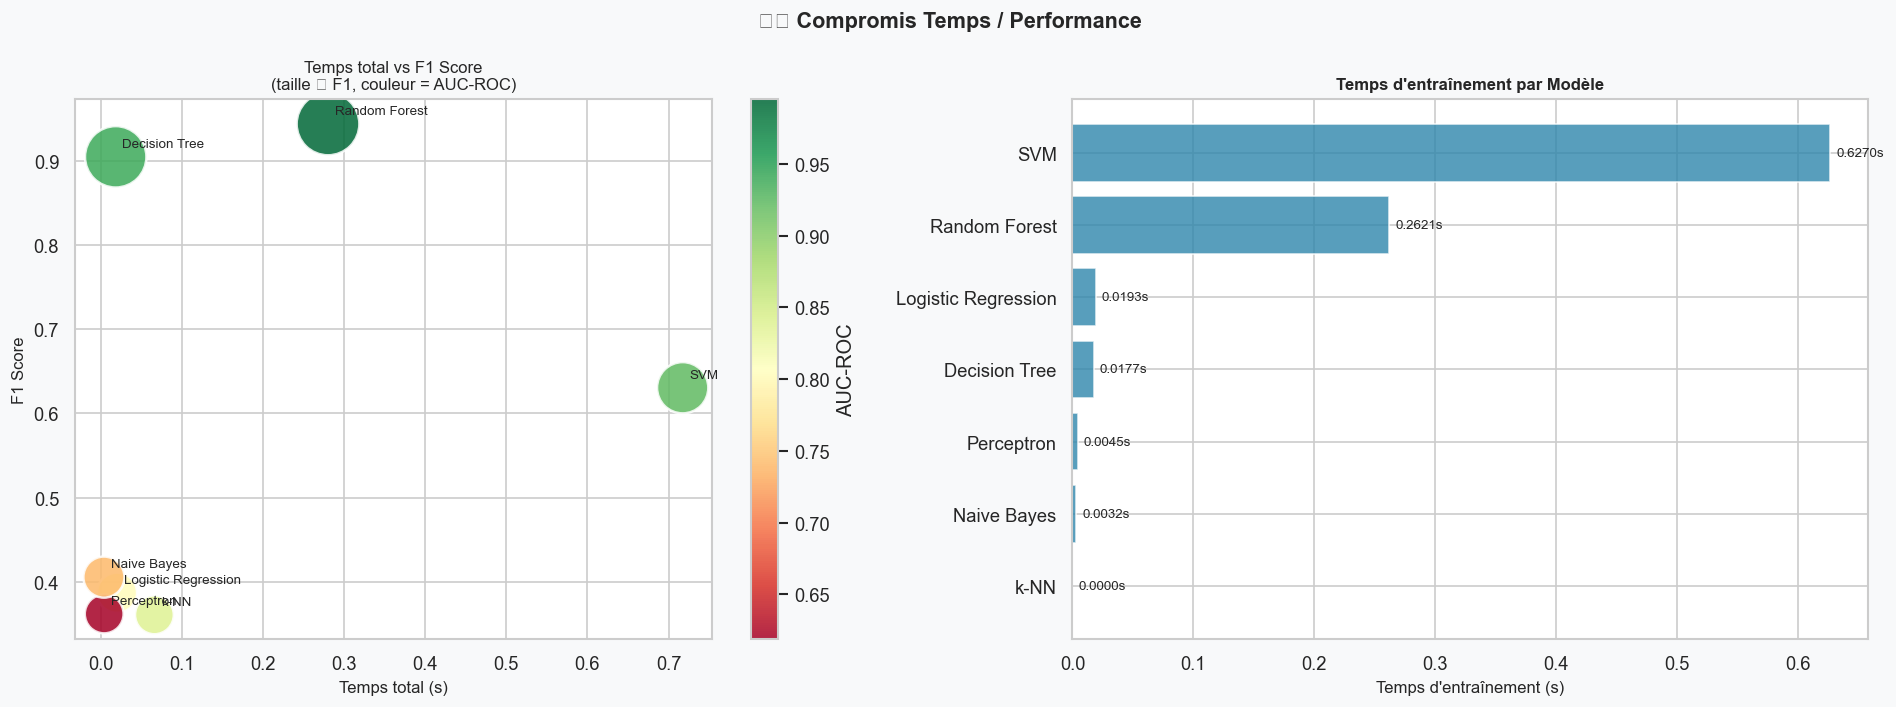

In [12]:
# ── Temps d'entraînement vs performance ─────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("⏱️ Compromis Temps / Performance", fontsize=13, fontweight='bold')

merged = metrics_df.merge(times_df, on='Model')
sizes  = merged['F1 Score'] * 1500

sc = ax1.scatter(merged['Total Time (s)'], merged['F1 Score'],
                 s=sizes, c=merged['AUC-ROC'],
                 cmap='RdYlGn', edgecolors='white', linewidths=1.5, alpha=0.85)
for _, row in merged.iterrows():
    ax1.annotate(row['Model'], (row['Total Time (s)'], row['F1 Score']),
                 fontsize=8, ha='left', va='bottom',
                 xytext=(4, 4), textcoords='offset points')
ax1.set_xlabel("Temps total (s)", fontsize=10)
ax1.set_ylabel("F1 Score", fontsize=10)
ax1.set_title("Temps total vs F1 Score\n(taille ∝ F1, couleur = AUC-ROC)", fontsize=10)
ax1.set_facecolor('white')
plt.colorbar(sc, ax=ax1, label='AUC-ROC')

# ── Barres : temps d'entraînement ───────────────────────────────────────────
times_sorted = times_df.sort_values('Training Time (s)', ascending=True)
bars = ax2.barh(times_sorted['Model'], times_sorted['Training Time (s)'],
                color=COLORS['primary'], alpha=0.8, edgecolor='white')
ax2.set_xlabel("Temps d'entraînement (s)", fontsize=10)
ax2.set_title("Temps d'entraînement par Modèle", fontsize=10, fontweight='bold')
ax2.set_facecolor('white')
for bar, v in zip(bars, times_sorted['Training Time (s)']):
    ax2.text(v + 0.005, bar.get_y() + bar.get_height()/2,
             f"{v:.4f}s", va='center', fontsize=8)

plt.tight_layout()
plt.show()

## 8. 🚀 Impact de l'Optimisation Bayésienne

Comparaison entre le **Random Forest de base** et les deux modèles optimisés (objectif Accuracy / objectif F1 Score).

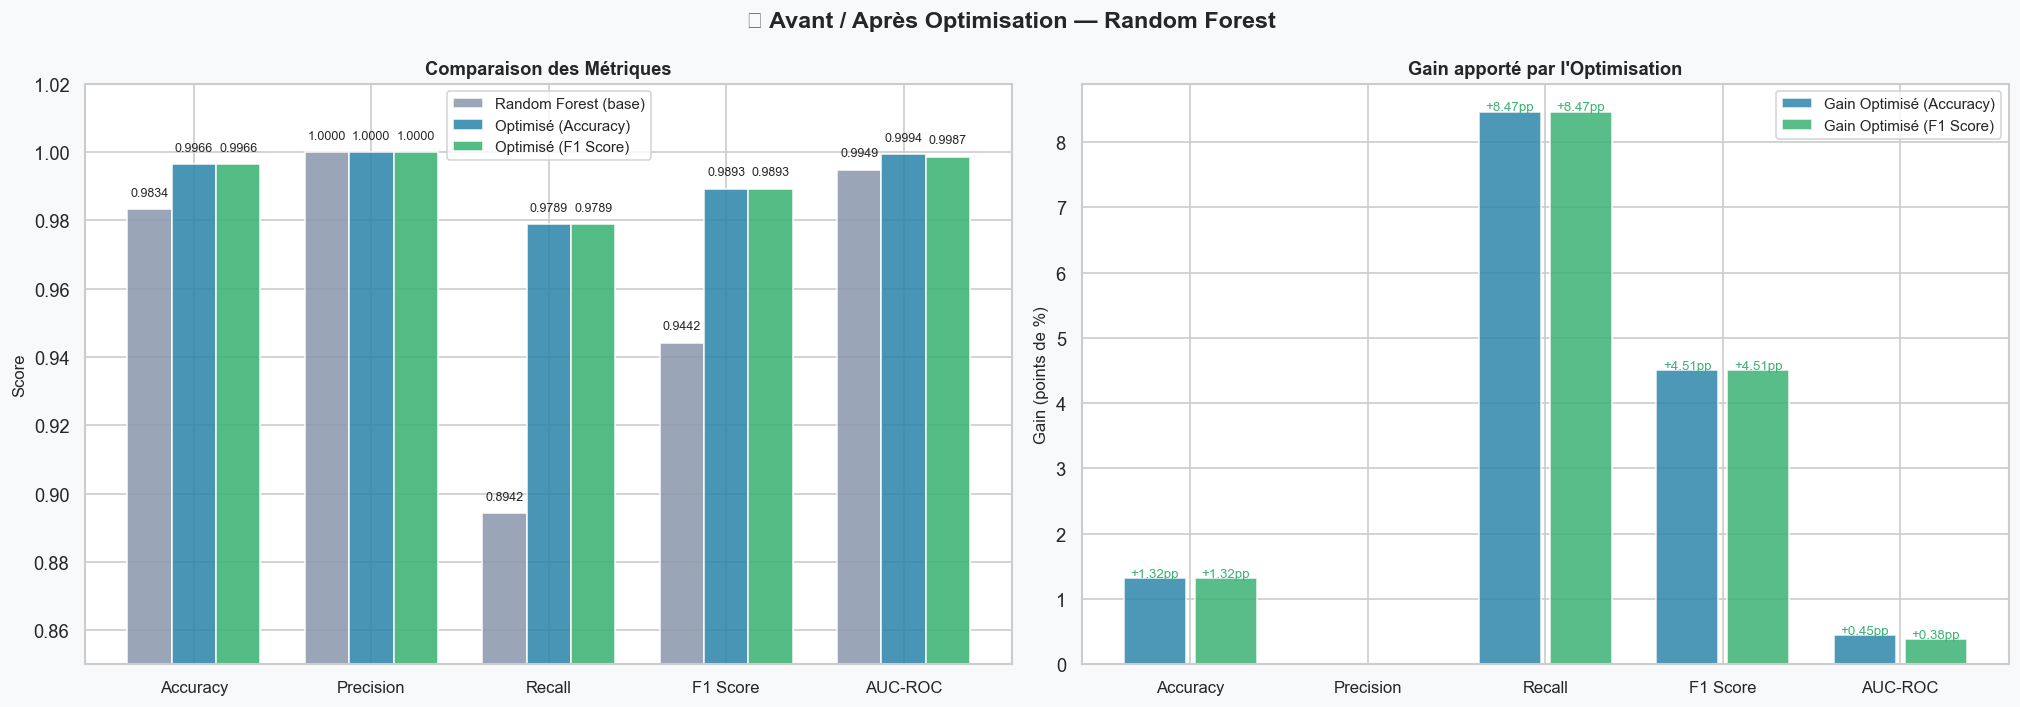


📋 Synthèse de l'optimisation :
                     Accuracy Precision  Recall F1 Score AUC-ROC
Random Forest (base)   0.9834       1.0  0.8942   0.9442  0.9949
Optimisé (Accuracy)    0.9966       1.0  0.9789   0.9893  0.9994
Optimisé (F1 Score)    0.9966       1.0  0.9789   0.9893  0.9987


In [13]:
# Base Random Forest (depuis model_comparison_metrics)
rf_base = metrics_df[metrics_df['Model'] == 'Random Forest'].iloc[0]

# Modèles optimisés
optim_acc = optim_df[optim_df['Modèle'] == 'Optimisé (Accuracy)'].iloc[0]
optim_f1  = optim_df[optim_df['Modèle'] == 'Optimisé (F1 Score)'].iloc[0]

compare_cols = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']

# Dataframe de comparaison
compare_df = pd.DataFrame({
    'Random Forest (base)':      rf_base[compare_cols].values,
    'Optimisé (Accuracy)':       optim_acc[compare_cols].values,
    'Optimisé (F1 Score)':       optim_f1[compare_cols].values,
}, index=compare_cols)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("🚀 Avant / Après Optimisation — Random Forest", fontsize=14, fontweight='bold')

# ── Subplot 1 : Barres groupées ─────────────────────────────────────────────
x = np.arange(len(compare_cols))
bar_w = 0.25
colors_cmp = [COLORS['neutral'], COLORS['primary'], COLORS['success']]
for i, (model_name, color) in enumerate(zip(compare_df.columns, colors_cmp)):
    offset = (i - 1) * bar_w
    bars = ax1.bar(x + offset, compare_df[model_name], bar_w, label=model_name,
                   color=color, alpha=0.88, edgecolor='white')
    for bar, v in zip(bars, compare_df[model_name]):
        ax1.text(bar.get_x() + bar.get_width()/2, v + 0.003, f"{v:.4f}",
                 ha='center', va='bottom', fontsize=7.5, rotation=0)

ax1.set_xticks(x)
ax1.set_xticklabels(compare_cols, fontsize=10)
ax1.set_ylim(0.85, 1.02)
ax1.set_ylabel("Score", fontsize=10)
ax1.set_title("Comparaison des Métriques", fontsize=11, fontweight='bold')
ax1.legend(fontsize=9)
ax1.set_facecolor('white')

# ── Subplot 2 : Gain apporté par l'optimisation ──────────────────────────────
gain_acc = ((compare_df['Optimisé (Accuracy)'] - compare_df['Random Forest (base)']) * 100)
gain_f1  = ((compare_df['Optimisé (F1 Score)']  - compare_df['Random Forest (base)']) * 100)

x = np.arange(len(compare_cols))
bars1 = ax2.bar(x - 0.2, gain_acc, 0.35, label='Gain Optimisé (Accuracy)',
                color=COLORS['primary'], alpha=0.85, edgecolor='white')
bars2 = ax2.bar(x + 0.2, gain_f1,  0.35, label='Gain Optimisé (F1 Score)',
                color=COLORS['success'], alpha=0.85, edgecolor='white')
ax2.axhline(0, color='black', linewidth=1)
ax2.set_xticks(x)
ax2.set_xticklabels(compare_cols, fontsize=10)
ax2.set_ylabel("Gain (points de %)", fontsize=10)
ax2.set_title("Gain apporté par l'Optimisation", fontsize=11, fontweight='bold')
ax2.legend(fontsize=9)
ax2.set_facecolor('white')
for bar, v in zip(list(bars1) + list(bars2), list(gain_acc) + list(gain_f1)):
    if abs(v) > 0.01:
        ax2.text(bar.get_x() + bar.get_width()/2,
                 v + (0.02 if v >= 0 else -0.06),
                 f"{v:+.2f}pp", ha='center', fontsize=8,
                 color=COLORS['success'] if v > 0 else COLORS['danger'])

plt.tight_layout()
plt.show()

print("\n📋 Synthèse de l'optimisation :")
print(compare_df.T.to_string())

## 9. 📝 Synthèse Exécutive — Recommandations RH

Résumé des enseignements clés issus de l'analyse et des modèles.

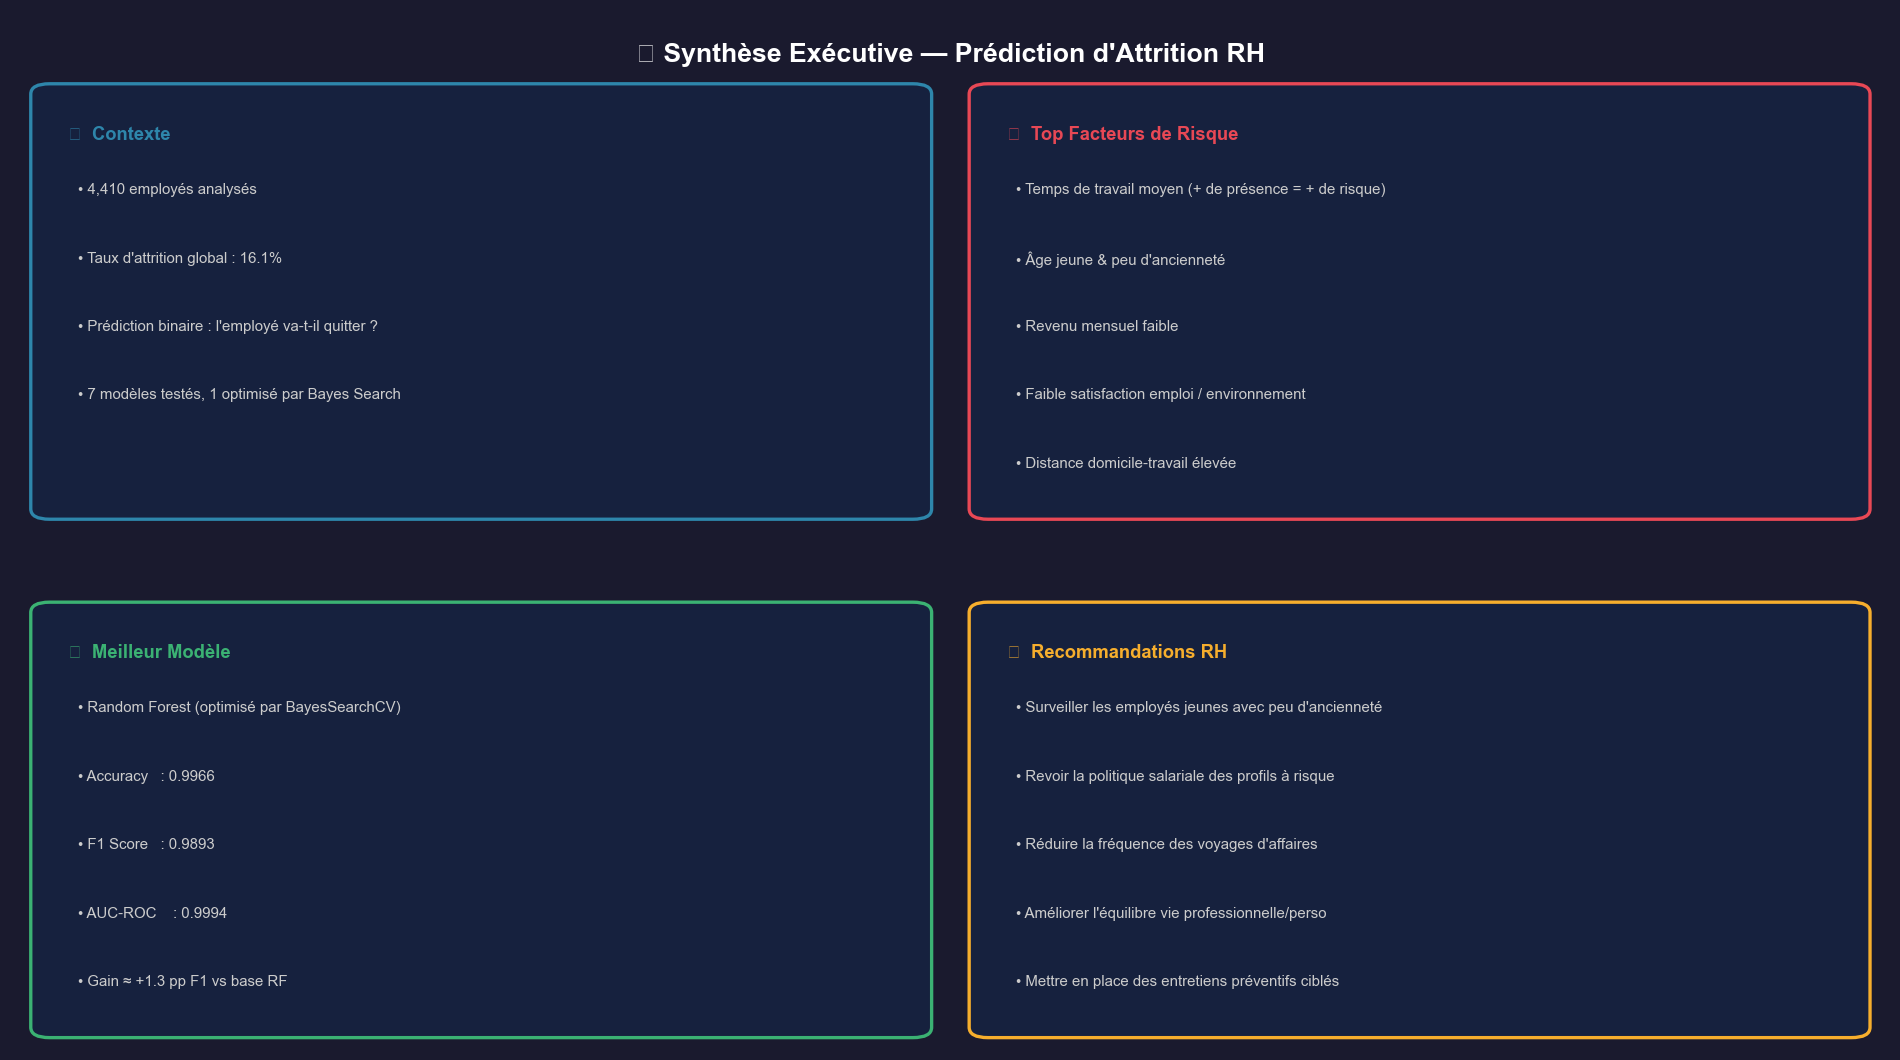

In [14]:
fig, ax = plt.subplots(figsize=(16, 9))
fig.patch.set_facecolor('#1A1A2E')
ax.set_facecolor('#1A1A2E')
ax.axis('off')

# ── Titre ───────────────────────────────────────────────────────────────────
ax.text(0.5, 0.97, "📝 Synthèse Exécutive — Prédiction d'Attrition RH",
        ha='center', va='top', fontsize=16, fontweight='bold', color='white',
        transform=ax.transAxes)

# ── 4 blocs ─────────────────────────────────────────────────────────────────
blocks = [
    {
        "title": "🎯  Contexte",
        "color": COLORS['primary'],
        "items": [
            f"• {total_emp:,} employés analysés",
            f"• Taux d'attrition global : {attr_rate:.1f}%",
            "• Prédiction binaire : l'employé va-t-il quitter ?",
            "• 7 modèles testés, 1 optimisé par Bayes Search",
        ]
    },
    {
        "title": "🔍  Top Facteurs de Risque",
        "color": COLORS['danger'],
        "items": [
            "• Temps de travail moyen (+ de présence = + de risque)",
            "• Âge jeune & peu d'ancienneté",
            "• Revenu mensuel faible",
            "• Faible satisfaction emploi / environnement",
            "• Distance domicile-travail élevée",
        ]
    },
    {
        "title": "🤖  Meilleur Modèle",
        "color": COLORS['success'],
        "items": [
            "• Random Forest (optimisé par BayesSearchCV)",
            f"• Accuracy   : {optim_acc['Accuracy']:.4f}",
            f"• F1 Score   : {optim_acc['F1 Score']:.4f}",
            f"• AUC-ROC    : {optim_acc['AUC-ROC']:.4f}",
            "• Gain ≈ +1.3 pp F1 vs base RF",
        ]
    },
    {
        "title": "💡  Recommandations RH",
        "color": COLORS['warning'],
        "items": [
            "• Surveiller les employés jeunes avec peu d'ancienneté",
            "• Revoir la politique salariale des profils à risque",
            "• Réduire la fréquence des voyages d'affaires",
            "• Améliorer l'équilibre vie professionnelle/perso",
            "• Mettre en place des entretiens préventifs ciblés",
        ]
    },
]

positions = [(0.02, 0.52), (0.52, 0.52), (0.02, 0.02), (0.52, 0.02)]
sizes     = [(0.46, 0.4),  (0.46, 0.4),  (0.46, 0.4),  (0.46, 0.4)]

for block, (bx, by), (bw, bh) in zip(blocks, positions, sizes):
    # Fond du bloc
    rect = mpatches.FancyBboxPatch((bx, by), bw, bh,
                                   boxstyle="round,pad=0.01",
                                   linewidth=2, edgecolor=block['color'],
                                   facecolor='#16213E',
                                   transform=ax.transAxes, zorder=2)
    ax.add_patch(rect)
    # Titre du bloc
    ax.text(bx + 0.01, by + bh - 0.03, block['title'],
            transform=ax.transAxes,
            fontsize=11, fontweight='bold', color=block['color'],
            va='top', zorder=3)
    # Items
    for j, item in enumerate(block['items']):
        ax.text(bx + 0.015, by + bh - 0.085 - j * 0.066, item,
                transform=ax.transAxes,
                fontsize=9, color='#CCCCCC', va='top', zorder=3)

plt.tight_layout()
plt.show()